# Clustering de municipios y oportunidades

Explora el número de clusters con inercia y silhouette. Después, selecciona visualmente `k` en la celda indicada y ejecuta las celdas de resultados.

In [1]:
import io
import logging
import sys
from pathlib import Path

import boto3
import pandas as pd
from botocore.exceptions import BotoCoreError, ClientError
from IPython.display import display

working_directory = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in (working_directory, *working_directory.parents)
        if (path / "src" / "procesado" / "tabla_oro.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.common.storage import get_storage_settings, s3_uri_for
from src.modelo.modelo import (
    crear_modelo_kmeans,
    graficar_clusters_interactivo,
    graficar_metricas_kmeans,
    graficar_metricas_y_obtener_mejor_k,
    seleccionar_y_guardar_municipios_candidatos,
)
from src.modelo.prepara_variables_modelo import (
    escalar_variables_modelo,
    seleccionar_variables_modelo,
    tasa_ponderada_de_competidores,
)
from src.procesado.common.paths import GOLD_TABLE_PATH

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s")

## Cargar la tabla Gold

Si S3 está configurado, se intenta leer desde `gold/`; ante un fallo se usa el Parquet local si existe.

In [2]:
storage_settings = get_storage_settings()
gold_s3_uri = s3_uri_for(GOLD_TABLE_PATH.name, "gold")

if storage_settings.save_s3 and gold_s3_uri:
    bucket_and_key = gold_s3_uri.removeprefix("s3://").split("/", 1)
    client_options = (
        {"region_name": storage_settings.region_name}
        if storage_settings.region_name
        else {}
    )
    try:
        response = boto3.client("s3", **client_options).get_object(
            Bucket=bucket_and_key[0],
            Key=bucket_and_key[1],
        )
        with response["Body"] as body:
            gold_municipios = pd.read_parquet(io.BytesIO(body.read()))
        print(f"Gold cargada desde {gold_s3_uri}")
    except (BotoCoreError, ClientError) as error:
        if not GOLD_TABLE_PATH.is_file():
            raise RuntimeError(
                f"No se pudo leer {gold_s3_uri} y no existe copia local en "
                f"{GOLD_TABLE_PATH}."
            ) from error
        logging.getLogger(__name__).warning(
            "No se pudo leer Gold desde S3; se usará la copia local: %s",
            error,
        )
        gold_municipios = pd.read_parquet(GOLD_TABLE_PATH)
else:
    if not GOLD_TABLE_PATH.is_file():
        raise FileNotFoundError(
            f"No se encontró la tabla Gold local: {GOLD_TABLE_PATH}; "
            "configura S3 o genera Gold primero."
        )
    gold_municipios = pd.read_parquet(GOLD_TABLE_PATH)
    print(f"Gold cargada desde {GOLD_TABLE_PATH}")

print(f"Municipios en Gold: {len(gold_municipios)}")
display(gold_municipios.head())

Gold cargada desde C:\Users\fatima.d.villalba\OneDrive - Accenture\Desktop\repos\market-expansion-sot\data\processed\gold\tabla_oro_municipios_andalucia.parquet
Municipios en Gold: 785


,municipality_code,municipality_name,province_code,province,population_year,population_total,population_18_50,population_growth_start_year,population_growth_pct,income_year,mean_net_income_per_person,gyms_count,other_sports_facilities_count
0,04001,Abla,04,Almería,2025,1267,464,2021,0.555556,2024,12836,0,1
1,04002,Abrucena,04,Almería,2025,1235,442,2021,1.89769,2024,12565,0,0
2,04003,Adra,04,Almería,2025,25579,11849,2021,0.380661,2024,10965,6,9
3,04004,Albanchez,04,Almería,2025,684,174,2021,-5.0,2024,12885,0,0
4,04005,Alboloduy,04,Almería,2025,578,216,2021,-5.863192,2024,11848,0,0


## Baseline

In [3]:
from src.modelo.baseline import top5_baseline
gold = gold_municipios
baseline = top5_baseline(gold).loc[:, [
    'municipality_code', 'municipality_name', 'province',
    'population_year', 'population_18_50',
]].reset_index(drop=True)
baseline.index = pd.RangeIndex(1, len(baseline) + 1, name='posicion')
display(baseline)

,municipality_code,municipality_name,province,population_year,population_18_50
posicion,,,,,
1,41091,Sevilla,Sevilla,2025,291636
2,29067,Málaga,Málaga,2025,262785
3,14021,Córdoba,Córdoba,2025,132660
4,18087,Granada,Granada,2025,97068
5,11020,Jerez de la Frontera,Cádiz,2025,90484


## Analizar datos antes de empezar con nuestro modelo

In [4]:
#Mirar valores que faltan
display(gold.isna().sum().rename('missing_values').to_frame())

,missing_values
municipality_code,0
municipality_name,0
province_code,0
province,0
population_year,0
population_total,0
population_18_50,0
population_growth_start_year,0
population_growth_pct,0
income_year,2


In [5]:
# Describir poblacion
gold.describe()

,population_year,population_total,population_18_50,population_growth_start_year,population_growth_pct,income_year,mean_net_income_per_person,gyms_count,other_sports_facilities_count
count,785.0,785.000000,785.000000,785.0,785.0,783.0,783.0,785.000000,785.000000
mean,2025.0,11053.137580,4732.952866,2021.0,0.709563,2024.0,12187.749681,0.721019,3.826752
std,0.0,40337.757679,17336.978530,0.0,5.209065,0.0,1323.998416,3.383239,10.080444
min,2025.0,55.000000,19.000000,2021.0,-18.777293,2024.0,8962.0,0.000000,0.000000
25%,2025.0,874.000000,331.000000,2021.0,-2.440106,2024.0,11311.5,0.000000,1.000000
50%,2025.0,2638.000000,1052.000000,2021.0,0.0,2024.0,11981.0,0.000000,2.000000
75%,2025.0,7403.000000,3102.000000,2021.0,3.266853,2024.0,12849.0,0.000000,4.000000
max,2025.0,688714.000000,291636.000000,2021.0,24.570447,2024.0,18019.0,47.000000,179.000000


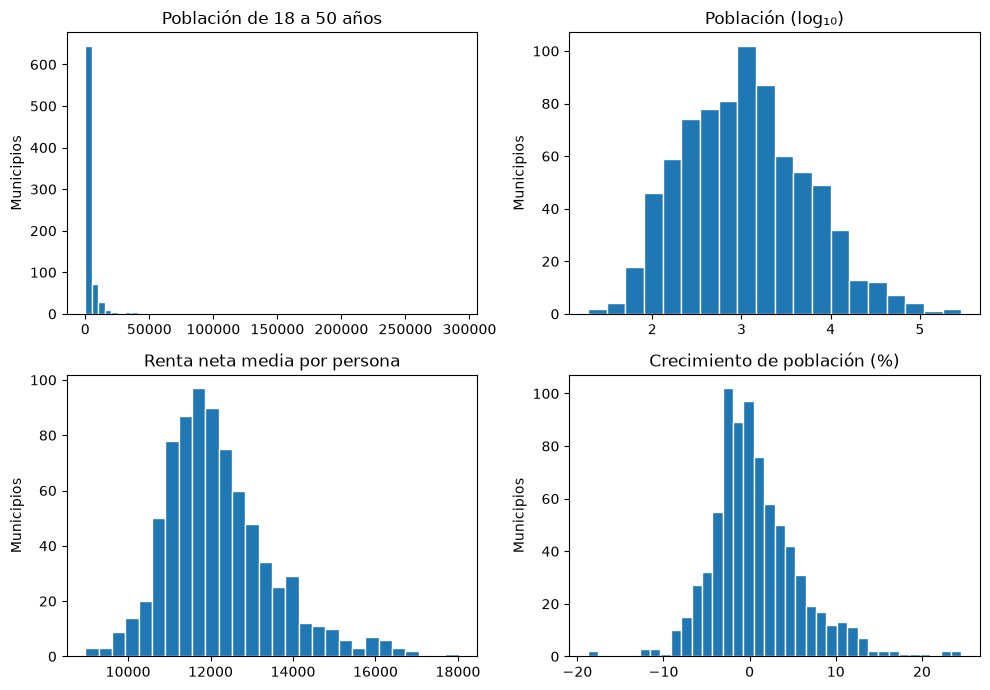

In [6]:
import matplotlib.pyplot as plt
import numpy as np
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

population = gold["population_18_50"].dropna()
income = gold["mean_net_income_per_person"].dropna()
growth = gold["population_growth_pct"].dropna()

axes[0, 0].hist(population, bins="auto", edgecolor="white")
axes[0, 0].set_title("Población de 18 a 50 años")

axes[0, 1].hist(np.log10(population[population > 0]), bins="auto", edgecolor="white")
axes[0, 1].set_title("Población (log₁₀)")

axes[1, 0].hist(income, bins="auto", edgecolor="white")
axes[1, 0].set_title("Renta neta media por persona")

axes[1, 1].hist(growth, bins="auto", edgecolor="white")
axes[1, 1].set_title("Crecimiento de población (%)")

for axis in axes.flat:
    axis.set_ylabel("Municipios")

plt.tight_layout()
plt.show()
    


In [7]:
# si skew por encima de 1 o por debajo de -1, la distribución es altamente asimétrica
variables = [
    'population_18_50',
    'population_growth_pct',
    'mean_net_income_per_person',
]

display(gold[variables].skew().rename('skew').to_frame())

,skew
population_18_50,11.399447
population_growth_pct,0.842289
mean_net_income_per_person,0.918156


--> Decidimos logaritmo de la poblacion porque está altamente sesgado

## Preparar variables de clustering

Los municipios con alguna variable ausente se muestran y se excluyen solo del clustering; permanecen en la tabla Gold.

In [8]:
variables_modelo = seleccionar_variables_modelo(gold_municipios)
mascara_completa = variables_modelo.notna().all(axis=1)
municipios_excluidos = gold_municipios.loc[~mascara_completa].copy()

if not municipios_excluidos.empty:
    print(
        f"Se excluyen {len(municipios_excluidos)} municipios del clustering "
        "por variables incompletas:"
    )
    columnas_exclusion = [
        columna
        for columna in ("municipality_code", "municipality_name")
        if columna in municipios_excluidos.columns
    ]
    municipios_excluidos = municipios_excluidos.loc[:, columnas_exclusion].copy()
    municipios_excluidos["variables_ausentes"] = variables_modelo.loc[
        ~mascara_completa
    ].apply(lambda fila: ", ".join(fila.index[fila.isna()]), axis=1)
    display(municipios_excluidos)

municipios_modelo = gold_municipios.loc[mascara_completa].reset_index(drop=True)
variables_modelo = seleccionar_variables_modelo(municipios_modelo)
if len(municipios_modelo) < 3:
    raise ValueError("Se necesitan al menos tres municipios completos para clustering.")

variables_escaladas = escalar_variables_modelo(variables_modelo)
print(f"Municipios incluidos en el clustering: {len(municipios_modelo)}")
display(variables_escaladas.head())

Se excluyen 2 municipios del clustering por variables incompletas:


,municipality_code,municipality_name,variables_ausentes
24,04026,Benitagla,mean_net_income_per_person
425,21027,Cumbres de Enmedio,mean_net_income_per_person


Municipios incluidos en el clustering: 783


,log1p_population_18_50,mean_net_income_per_person,population_growth_pct
0,-0.546240,0.489929,-0.027404
1,-0.576717,0.285115,0.230460
2,1.489857,-0.924118,-0.061006
3,-1.160740,0.526961,-1.094789
4,-1.025477,-0.256773,-1.260634


## Explorar el número de clusters

Los gráficos son complementarios: busca el codo en la inercia y compara las puntuaciones silhouette. No hay un `k` universalmente correcto; elige uno razonable para los datos y el objetivo de negocio.

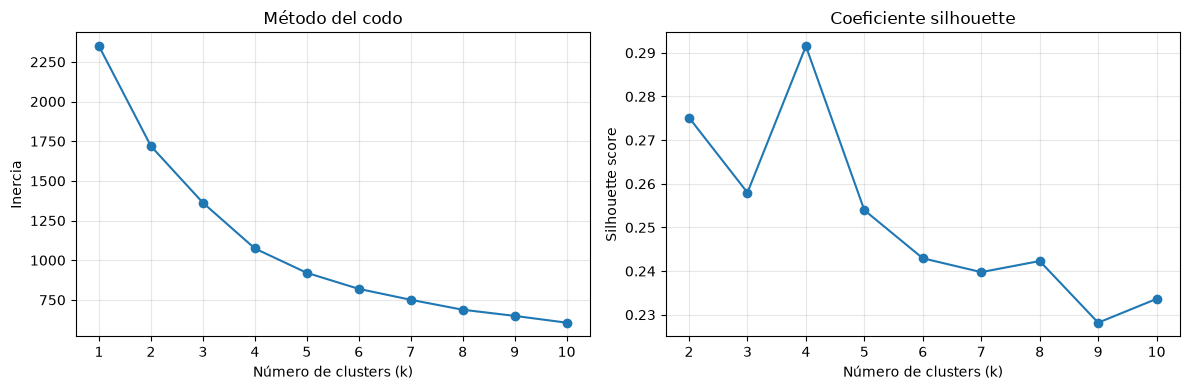

     inercia  silhouette
k                       
1   2349.000         NaN
2   1718.827       0.275
3   1362.205       0.258
4   1074.023       0.292
5    920.608       0.254
6    819.514       0.243
7    750.821       0.240
8    688.115       0.242
9    649.370       0.228
10   606.588       0.234

k recomendado por silhouette: 4 (la inercia se usa para valorar visualmente el codo).


In [9]:
k_mejor_silhouette = graficar_metricas_y_obtener_mejor_k(
    variables_escaladas.to_numpy()
)

## Elegir `k` y entrenar el modelo

Después de revisar los gráficos, cambia `N_CLUSTERS` por el valor elegido y ejecuta esta celda y las siguientes. Por ejemplo, si eliges cuatro grupos, asigna `N_CLUSTERS = 4`.

In [10]:
N_CLUSTERS = 4  # Sustituir por el k elegido tras revisar los gráficos.

if N_CLUSTERS is None:
    raise ValueError(
        "Elige N_CLUSTERS según los gráficos de inercia y silhouette "
        "y vuelve a ejecutar esta celda."
    )

modelo_kmeans = crear_modelo_kmeans(
    N_CLUSTERS,
    variables_escaladas.to_numpy(),
)
municipios_modelo["cluster"] = modelo_kmeans.labels_
print(f"Modelo entrenado con {N_CLUSTERS} clusters.")

Modelo entrenado con 4 clusters.


## Explorar los clusters

La figura muestra tres relaciones entre variables y tres boxplots por cluster. Los puntos y las distribuciones usan los valores originales; la población se representa con escala logarítmica. KMeans, en cambio, se entrenó con las variables transformadas y estandarizadas.

In [11]:
figura_pares_clusters = graficar_clusters_interactivo(
    variables_escaladas,
    municipios_modelo,
    modelo_kmeans.labels_,
)
display(figura_pares_clusters)

### Perfil Clusters

In [12]:
resumen_clusters = municipios_modelo.copy()
cluster_profile = (
    resumen_clusters
      .groupby("cluster")
      .agg(
          municipios=("municipality_name", "count"),
          pob18_50_media=("population_18_50", "mean"),
          pob18_50_mediana=("population_18_50", "median"),
          renta_media=("mean_net_income_per_person", "mean"),
          crecimiento_medio=("population_growth_pct", "mean")
      )
      .round({
          "pob18_50_media": 0,
          "pob18_50_mediana": 0,
          "renta_media": 0,
          "crecimiento_medio": 2
      })
)
display(cluster_profile)

,municipios,pob18_50_media,pob18_50_mediana,renta_media,crecimiento_medio
cluster,,,,,
0,96,1253.0,578.0,11791.0,9.85
1,204,305.0,229.0,12931.0,-3.09
2,362,2486.0,1457.0,11398.0,-0.48
3,121,21758.0,9461.0,13612.0,3.35


### Características de los clusters

Según las gráficas y el perfil medio, los clusters se distinguen principalmente por el tamaño de su población, la renta y la evolución demográfica:

- **Cluster 0 — Municipios pequeños en crecimiento:** tienen una población media de **1.253 personas de 18 a 50 años** (mediana: 578) y una renta media de **11.791 €**. Destacan por su crecimiento poblacional medio, de **9,85 %**.
- **Cluster 1 — Municipios muy pequeños y en descenso:** presentan la menor población media (**305**, mediana: 229) y un crecimiento medio negativo (**−3,09 %**). Su renta media es de **12.931 €**.
- **Cluster 2 — Municipios de tamaño intermedio y estables:** registran una población media de **2.486 personas** (mediana: 1.457), la renta media más baja (**11.398 €**) y un crecimiento ligeramente negativo (**−0,48 %**).
- **Cluster 3 — Municipios grandes y con mayor renta:** agrupan los municipios con más población (**21.758 personas de media**, mediana: 9.461) y la renta media más alta (**13.612 €**). Su crecimiento medio también es positivo (**3,35 %**).

Las medias de población pueden verse afectadas por municipios muy poblados; por eso, la mediana ayuda a entender mejor el tamaño típico de cada grupo. Los números de cluster son etiquetas asignadas por KMeans, no categorías ordenadas.

## Seleccionar municipios candidatos

La tasa ponderada cuenta cada gimnasio como 1 instalación y cada otra instalación deportiva como 0,1, por cada 100.000 habitantes. Se seleccionan municipios estrictamente por debajo de la media de su propio cluster.

In [13]:
candidatos = seleccionar_y_guardar_municipios_candidatos(
    municipios_modelo,
    municipios_modelo["cluster"],
)

print(f"Municipios seleccionados: {len(candidatos)}")
display(candidatos)

Municipios seleccionados: 562


,municipality_code,municipality_name,province_code,province,population_year,population_total,population_18_50,population_growth_start_year,population_growth_pct,income_year,mean_net_income_per_person,gyms_count,other_sports_facilities_count,cluster,tasa_ponderada_de_competidores,media_tasa_ponderada_cluster
0,04001,Abla,04,Almería,2025,1267,464,2021,0.555556,2024,12836,0,1,1,7.892660,28.792748
1,04002,Abrucena,04,Almería,2025,1235,442,2021,1.89769,2024,12565,0,0,1,0.000000,28.792748
3,04004,Albanchez,04,Almería,2025,684,174,2021,-5.0,2024,12885,0,0,1,0.000000,28.792748
4,04005,Alboloduy,04,Almería,2025,578,216,2021,-5.863192,2024,11848,0,0,1,0.000000,28.792748
6,04007,Alcolea,04,Almería,2025,831,285,2021,-2.579132,2024,11594,0,1,1,12.033694,28.792748
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
775,41099,Villanueva del Río y Minas,41,Sevilla,2025,5079,2074,2021,3.273688,2024,10788,0,1,2,1.968892,12.482330
776,41100,Villanueva de San Juan,41,Sevilla,2025,980,351,2021,-8.837209,2024,11249,0,0,1,0.000000,28.792748
780,41902,Isla Mayor,41,Sevilla,2025,5760,2492,2021,-1.352971,2024,10100,0,6,2,10.416667,12.482330
781,41903,"Cuervo de Sevilla, El",41,Sevilla,2025,8779,3882,2021,1.526541,2024,10378,0,4,2,4.556328,12.482330
